# 01 — Uploaded Dataset EDA

This notebook uses the uploaded `Diabetes Dataset(1).csv`. Inspect its real schema and categorical target rather than assuming it matches a different diabetes dataset.

In [5]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
from src.preprocessing import quality_report, descriptive_statistics, candidate_clean
from src.visualization import plot_target, plot_distributions, plot_boxplots, plot_correlations, plot_missingness, plot_target_association
from src.data_loading import load_uploaded
df = load_uploaded()
target = "Outcome"
print("Shape:", df.shape, "| duplicate rows:", df.duplicated().sum())
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Shape: (20000, 15) | duplicate rows: 0


,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


,dtype
Gender,str
Age,int64
Physical Activity,str
Smoking Status,str
Alcohol Intake,str
Glucose,int64
Blood Pressure,int64
Skin Thickness,int64
Insulin,int64
BMI,float64


## Target distribution and quality

Class balance matters: a majority-class dataset can make a naïve classifier look deceptively useful. Missingness, duplicate rows, ranges and unique values should be reviewed before cleaning.

In [6]:
display(df[target].value_counts(dropna=False).rename("count").to_frame())
display((df[target].value_counts(normalize=True, dropna=False)*100).round(2).rename("percent").to_frame())
display(quality_report(df))
display(descriptive_statistics(df))

,count
Outcome,
Diabetic,16726
Non-diabetic,3274


,percent
Outcome,
Diabetic,83.63
Non-diabetic,16.37


,feature,dtype,missing_count,missing_percent,unique_values,minimum,maximum
0,Gender,str,0,0.000,2,NaN,NaN
1,Age,int64,0,0.000,60,20.0,79.0
2,Physical Activity,str,0,0.000,3,NaN,NaN
3,Smoking Status,str,0,0.000,3,NaN,NaN
4,Alcohol Intake,str,9925,49.625,2,NaN,NaN
5,Glucose,int64,0,0.000,161,40.0,200.0
6,Blood Pressure,int64,0,0.000,84,30.0,114.0
7,Skin Thickness,int64,0,0.000,48,7.0,57.0
8,Insulin,int64,0,0.000,256,15.0,276.0
9,BMI,float64,0,0.000,19757,15.0,50.0


,feature,count,mean,std,min,5%,25%,50%,75%,95%,max,missing,variance,skewness,iqr
0,Age,20000.0,49.565400,17.320956,20.0,22.000000,35.000000,50.00000,64.000000,77.00000,79.0,0,300.015524,-0.001846,29.000000
1,Glucose,20000.0,119.603400,29.590699,40.0,71.000000,99.000000,120.00000,140.000000,169.00000,200.0,0,875.609489,0.001392,41.000000
2,Blood Pressure,20000.0,69.432850,12.016115,30.0,50.000000,61.000000,69.00000,78.000000,89.00000,114.0,0,144.387010,-0.011413,17.000000
3,Skin Thickness,20000.0,20.105450,9.130969,7.0,7.000000,13.000000,20.00000,26.000000,36.00000,57.0,0,83.374599,0.402495,13.000000
4,Insulin,20000.0,83.952550,53.026841,15.0,15.000000,40.000000,79.00000,120.000000,180.00000,276.0,0,2811.845891,0.534908,80.000000
5,BMI,20000.0,32.008980,6.913271,15.0,20.449993,27.314424,31.99404,36.750196,43.45665,50.0,0,47.793318,0.018217,9.435772
6,Cholesterol,20000.0,189.555400,35.081701,100.0,132.000000,166.000000,190.00000,213.000000,248.00000,320.0,0,1230.725767,0.029942,47.000000
7,Diabetes Pedigree Function,20000.0,1.310665,0.693984,0.1,0.229950,0.704750,1.31600,1.914000,2.38700,2.5,0,0.481613,-0.013841,1.209250


## Plots

Histograms show distribution and skew; boxplots show spread and potential outliers; correlation is only a first-pass linear association for numeric columns.

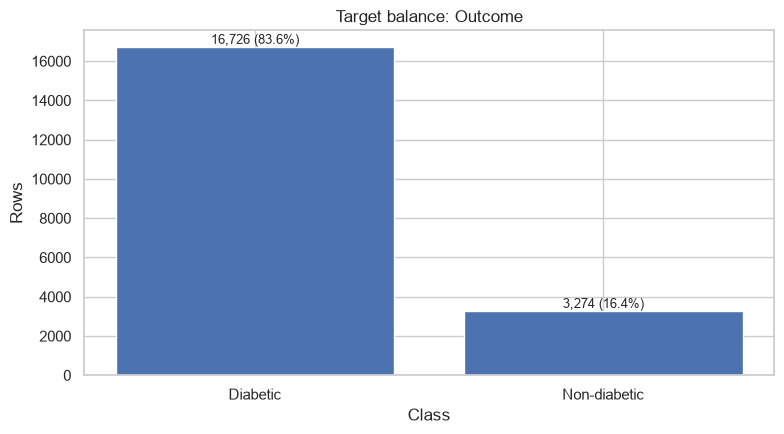

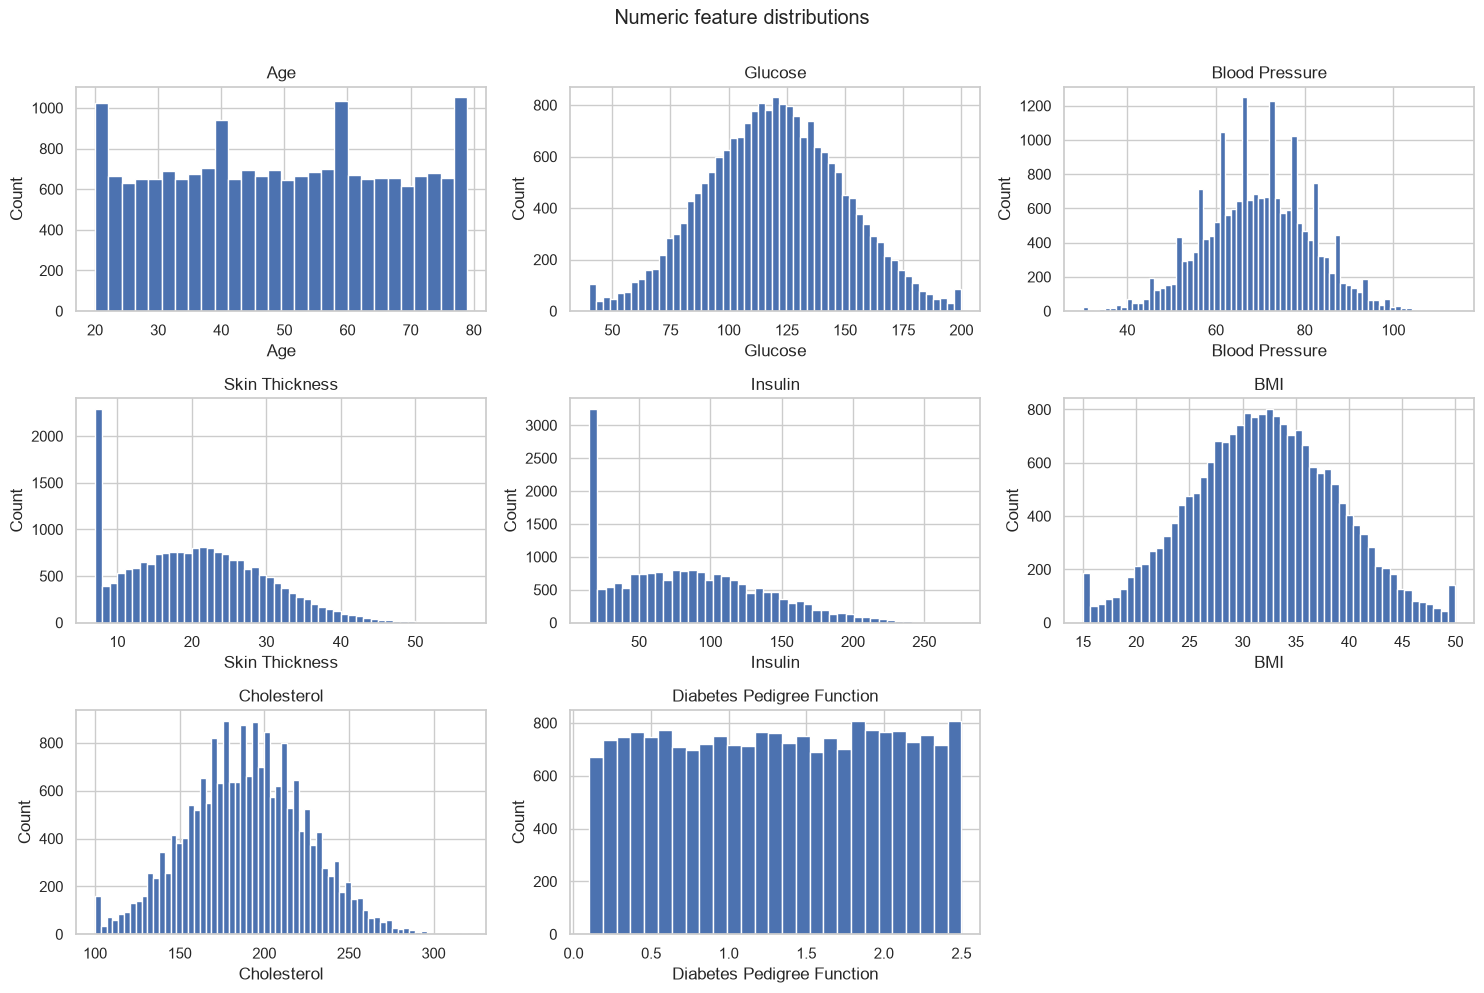

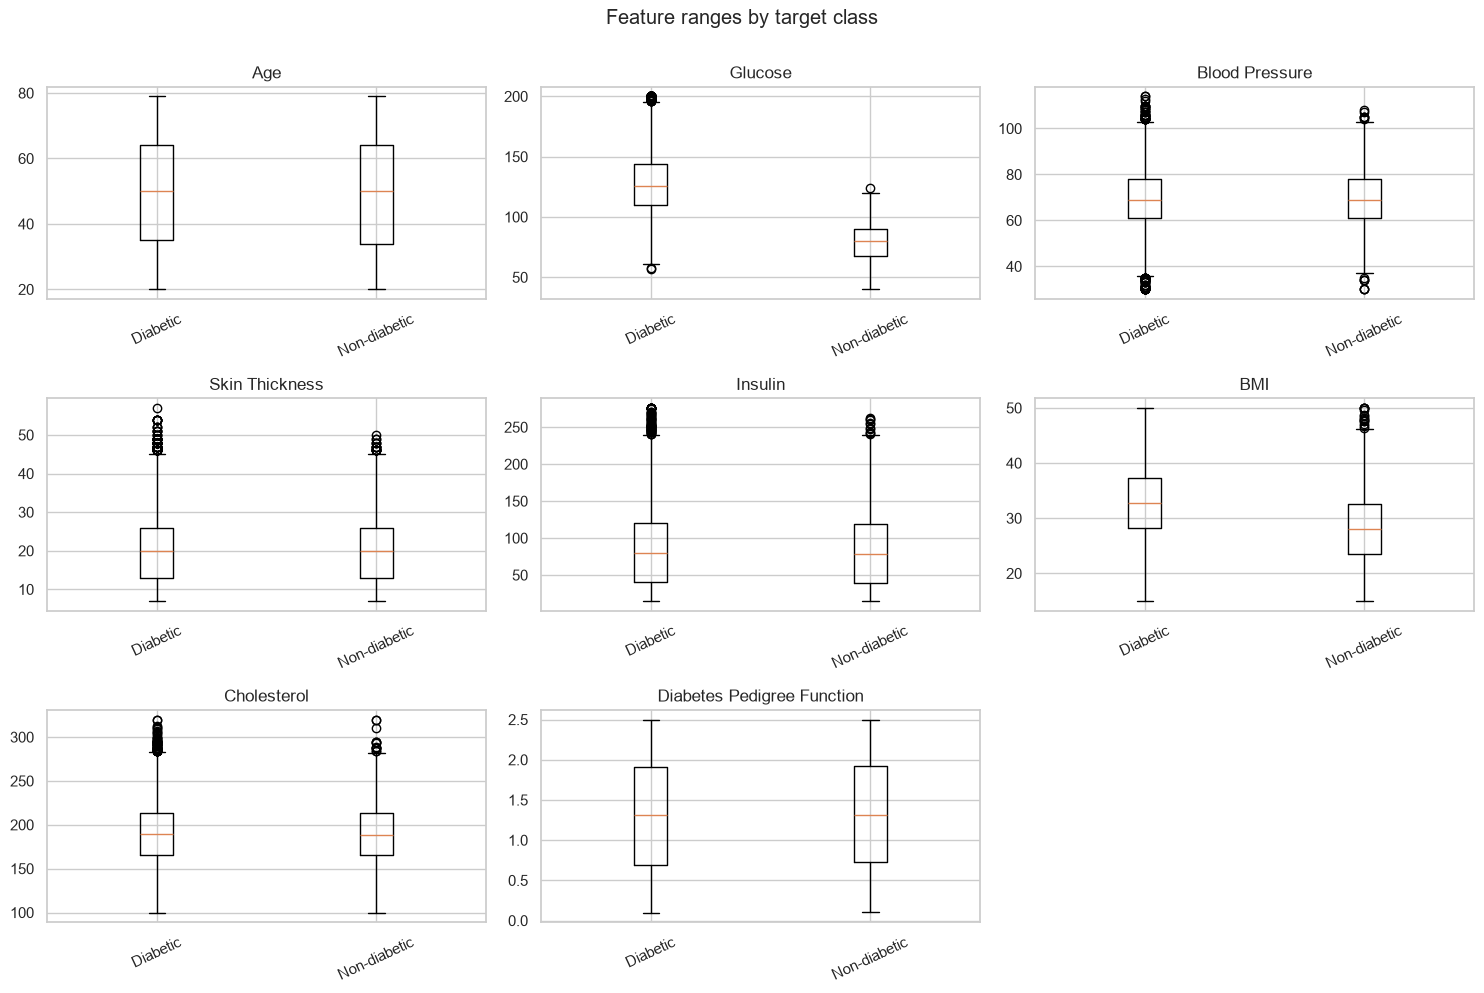

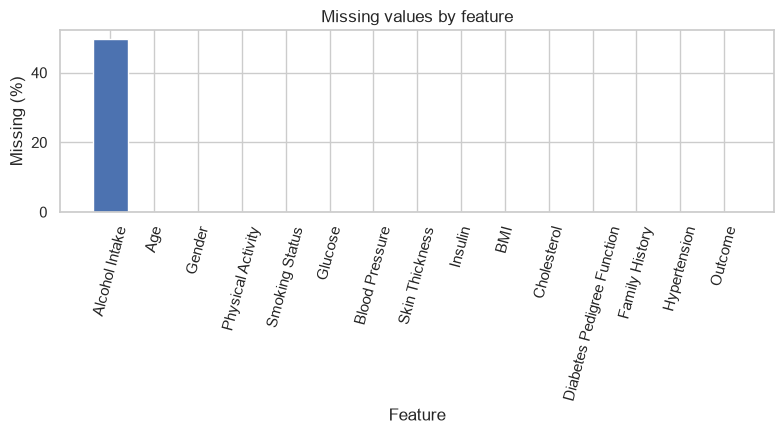

In [7]:
out = ROOT / "outputs" / "figures" / "uploaded"
plot_target(df, target, out)
plot_distributions(df, target, out)
plot_boxplots(df, target, out)
plot_missingness(df, out)
plot_correlations(df, target, out)
plot_target_association(df, target, out)
plt.show()

## Candidate preprocessing

This baseline imputes actual NaNs only (numeric median, categorical `Unknown`). It does not blindly replace zero values. For predictive modelling, learned imputers must be fitted on training data only.

In [ ]:
processed = candidate_clean(df)
print("Missing before:", int(df.isna().sum().sum()), "after:", int(processed.isna().sum().sum()))
display(quality_report(processed))
report_dir = ROOT / "outputs" / "reports" / "uploaded"
report_dir.mkdir(parents=True, exist_ok=True)
quality_report(df).to_csv(report_dir / "data_quality.csv", index=False)
descriptive_statistics(df).to_csv(report_dir / "descriptive_statistics.csv", index=False)

Missing before: 9925 after: 0


,feature,dtype,missing_count,missing_percent,unique_values,minimum,maximum
0,Gender,str,0,0.0,2,NaN,NaN
1,Age,int64,0,0.0,60,20.0,79.0
2,Physical Activity,str,0,0.0,3,NaN,NaN
3,Smoking Status,str,0,0.0,3,NaN,NaN
4,Alcohol Intake,str,0,0.0,3,NaN,NaN
5,Glucose,int64,0,0.0,161,40.0,200.0
6,Blood Pressure,int64,0,0.0,84,30.0,114.0
7,Skin Thickness,int64,0,0.0,48,7.0,57.0
8,Insulin,int64,0,0.0,256,15.0,276.0
9,BMI,float64,0,0.0,19757,15.0,50.0


: 